# Evaluación Sumativa 3: Modelamiento Predictivo Integrado

## Predicción de enfermedad coronaria a diez años

**Entregable:** Notebook de análisis  
**Curso:** MCDI501 — Estadística Computacional para la Toma de Decisiones  
**Programa:** Magíster en Ciencia de Datos  
**Universidad:** Universidad Andrés Bello  

| Campo | Información |
|---|---|
| **Estudiante** | Alexander Sepúlveda Ormazábal |
| **Dataset** | Framingham Heart Study |
| **Variable objetivo** | `TenYearCHD` |
| **Fecha de entrega** | 28 de octubre de 2026 |
| **Repositorio GitHub** | https://github.com/alexander-seor/MCDI501-Proyecto-Framingham |

## Integración del proyecto: S1 → S2 → S3

La Sumativa 1 cuantificó los datos faltantes, describió valores extremos y asimetrías, y exploró asociaciones bivariadas con `TenYearCHD`. Debido al carácter observacional de los datos, estos resultados se interpretaron como asociaciones y no como relaciones causales.

La Sumativa 2 evaluó la estabilidad y robustez interna de distintos resultados mediante bootstrap, una prueba de permutación y análisis de sensibilidad. Además, utilizó simulación Monte Carlo para estudiar la variabilidad de la tasa de enfermedad coronaria en cohortes hipotéticas. Estos procedimientos no constituyen una validación externa ni una evaluación del desempeño predictivo.

En la Sumativa 3, los resultados anteriores orientan el tratamiento de los datos faltantes y la definición de modelos candidatos. Se comparan eliminación de casos, imputación simple e imputación por regresión; luego se construyen tres modelos logísticos: uno informado por S1/S2, uno mediante selección *stepwise* y otro basado en BIC.

El objetivo es comparar modelos capaces de distinguir perfiles con mayor o menor probabilidad de desarrollar enfermedad coronaria a diez años. Como el clasificador utiliza ponderación de clases y no se realiza una evaluación formal de calibración, sus puntuaciones no deben interpretarse como riesgos clínicos individuales calibrados.

## 0. Configuración y carga de datos



In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score,
)
from sklearn.model_selection import (
    train_test_split,
    KFold,
    StratifiedKFold,
    cross_val_score,
    cross_validate,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from IPython.display import display

# Se ocultan solo avisos futuros de compatibilidad. Los avisos de convergencia
# permanecen visibles porque forman parte del diagnóstico del modelamiento.
warnings.filterwarnings("ignore", category=FutureWarning)

SEMILLA = 42
rng = np.random.default_rng(SEMILLA)
TARGET = "TenYearCHD"

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (10, 6), "figure.dpi": 110})

print("Bibliotecas cargadas correctamente.")
print("Semilla configurada:", SEMILLA)
print("Variable objetivo:", TARGET)

Bibliotecas cargadas correctamente.
Semilla configurada: 42
Variable objetivo: TenYearCHD


### Verificación de la configuración

Se establece la semilla `42` para que los procedimientos aleatorios puedan reproducirse. La variable `TenYearCHD` se define como objetivo del modelamiento y representa si la persona desarrolló enfermedad coronaria durante los diez años de seguimiento.

En esta etapa solo se prepara el entorno de trabajo. Todavía no se realizan transformaciones, imputaciones ni ajustes de modelos sobre los datos.

### Preparación y procedencia de los datos

El archivo original se localiza dentro del repositorio y se carga sin modificarlo. El análisis se realiza sobre una copia en memoria. También se comprueban sus dimensiones, la existencia de la variable objetivo y la presencia de registros duplicados antes de aplicar cualquier transformación.

In [2]:
def encontrar_raiz(inicio=None):
    inicio = Path(inicio or Path.cwd()).resolve()
    for candidata in (inicio, *inicio.parents):
        archivo = candidata / "fase-1" / "datos" / "raw" / "framingham.csv"
        if archivo.exists():
            return candidata
    raise FileNotFoundError(
        "No se encontró fase-1/datos/raw/framingham.csv. "
        "Inicie Jupyter dentro del repositorio MCDI501-Framingham."
    )


RAIZ = encontrar_raiz()
RUTA_DATOS = RAIZ / "fase-1" / "datos" / "raw" / "framingham.csv"
DIR_S3 = RAIZ / "fase-4" / "sumativa-3"
DIR_FIGURAS = DIR_S3 / "figuras"
DIR_RESULTADOS = DIR_S3 / "resultados"
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)
DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)

df_original = pd.read_csv(RUTA_DATOS)
df = df_original.copy()

if TARGET not in df.columns:
    raise KeyError(f"La variable objetivo {TARGET!r} no está presente en el dataset.")

print("Archivo cargado:", RUTA_DATOS)
print(f"Dimensiones: {df.shape[0]:,} filas y {df.shape[1]} columnas")
print("Filas duplicadas:", int(df.duplicated().sum()))
print("Variable objetivo presente:", TARGET in df.columns)
display(df.head())

Archivo cargado: C:\MCDI501-Framingham\fase-1\datos\raw\framingham.csv
Dimensiones: 4,238 filas y 16 columnas
Filas duplicadas: 0
Variable objetivo presente: True


,male,age,education,currentSmoker,cigsPerDay,BPMeds,prevalentStroke,prevalentHyp,diabetes,totChol,sysBP,diaBP,BMI,heartRate,glucose,TenYearCHD
0,1,39,4.0,0,0.0,0.0,0,0,0,195.0,106.0,70.0,26.97,80.0,77.0,0
1,0,46,2.0,0,0.0,0.0,0,0,0,250.0,121.0,81.0,28.73,95.0,76.0,0
2,1,48,1.0,1,20.0,0.0,0,0,0,245.0,127.5,80.0,25.34,75.0,70.0,0
3,0,61,3.0,1,30.0,0.0,0,1,0,225.0,150.0,95.0,28.58,65.0,103.0,1
4,0,46,3.0,1,23.0,0.0,0,0,0,285.0,130.0,84.0,23.10,85.0,85.0,0


### Interpretación de la carga

El archivo contiene 4.238 observaciones y 16 variables, sin filas duplicadas. La variable `TenYearCHD` está disponible y se conserva el archivo original sin transformaciones. Esto coincide con la base utilizada en S1 y S2 y permite mantener la trazabilidad entre las tres etapas del proyecto.

## 1. Tratamiento de datos faltantes

### 1.1 Referencia al análisis de faltantes de S1

S1 cuantificó los valores ausentes y mostró que `glucose` concentra la mayor proporción, seguida por `education`, `BPMeds`, `totChol`, `cigsPerDay`, `BMI` y `heartRate`. S1 no estableció formalmente un mecanismo MCAR, MAR o MNAR. Por ello, en esta etapa se adopta **MAR como supuesto de trabajo**, no como certeza: se considera que parte de la ausencia puede explicarse mediante variables observadas. Un mecanismo MNAR no puede descartarse solo con estos datos.

Antes de ajustar imputadores se realiza una partición estratificada 70/30. De esta manera, todos los parámetros de imputación se estiman únicamente con entrenamiento y se evita utilizar información del conjunto de prueba.

In [3]:
faltantes_s1 = pd.DataFrame({
    "faltantes": df.isna().sum(),
    "porcentaje": 100 * df.isna().mean(),
}).query("faltantes > 0").sort_values("porcentaje", ascending=False)

indices_train, indices_test = train_test_split(
    df.index,
    test_size=0.30,
    random_state=SEMILLA,
    stratify=df[TARGET],
)

train_original = df.loc[indices_train].copy()
test_original = df.loc[indices_test].copy()

resumen_particion = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Prueba"],
    "n": [len(train_original), len(test_original)],
    "CHD (%)": [100 * train_original[TARGET].mean(), 100 * test_original[TARGET].mean()],
})

display(faltantes_s1.round(2))
display(resumen_particion.round(2))
print("Intersección de índices:", len(set(indices_train) & set(indices_test)))

,faltantes,porcentaje
glucose,388,9.16
education,105,2.48
BPMeds,53,1.25
totChol,50,1.18
cigsPerDay,29,0.68
BMI,19,0.45
heartRate,1,0.02


,Conjunto,n,CHD (%)
0,Entrenamiento,2966,15.21
1,Prueba,1272,15.17


Intersección de índices: 0


### Interpretación de los faltantes y la partición

La glucosa presenta 388 valores faltantes (9,16 %), mientras que las demás variables no superan el 2,5 %. La partición conserva prácticamente la misma proporción de CHD en entrenamiento y prueba y no comparte observaciones entre ambos conjuntos. La separación se fija desde este punto y será reutilizada en todas las estrategias de imputación y modelos.

### 1.2 Imputación mediante regresión lineal múltiple

La imputación por regresión se aplica a las variables cuantitativas con faltantes: `cigsPerDay`, `totChol`, `BMI`, `heartRate` y `glucose`. `education` es ordinal y `BPMeds` es dicotómica; por tanto, se imputan con la moda de entrenamiento, porque una regresión lineal podría producir categorías inexistentes.

Para cada variable cuantitativa se utilizan cuatro predictores seleccionados a partir de la matriz de correlaciones de S1. Los modelos se evalúan mediante validación cruzada dentro del conjunto de entrenamiento. Las predicciones se acotan al rango observado en entrenamiento para evitar valores imposibles.

In [4]:
PREDICTORES_IMPUTACION = {
    "cigsPerDay": ["currentSmoker", "male", "age", "BMI"],
    "totChol": ["age", "sysBP", "diaBP", "prevalentHyp"],
    "BMI": ["diaBP", "sysBP", "prevalentHyp", "currentSmoker"],
    "heartRate": ["sysBP", "diaBP", "prevalentHyp", "male"],
    "glucose": ["diabetes", "sysBP", "age", "heartRate"],
}

VARIABLES_CATEGORICAS_FALTANTES = ["education", "BPMeds"]


def ajustar_imputacion_simple(train, test):
    train_imp, test_imp = train.copy(), test.copy()
    columnas_numericas = [
        "cigsPerDay", "totChol", "BMI", "heartRate", "glucose"
    ]
    imp_num = SimpleImputer(strategy="median")
    imp_cat = SimpleImputer(strategy="most_frequent")
    train_imp[columnas_numericas] = imp_num.fit_transform(train[columnas_numericas])
    test_imp[columnas_numericas] = imp_num.transform(test[columnas_numericas])
    train_imp[VARIABLES_CATEGORICAS_FALTANTES] = imp_cat.fit_transform(
        train[VARIABLES_CATEGORICAS_FALTANTES]
    )
    test_imp[VARIABLES_CATEGORICAS_FALTANTES] = imp_cat.transform(
        test[VARIABLES_CATEGORICAS_FALTANTES]
    )
    return train_imp, test_imp


def ajustar_imputacion_regresion(train, test):
    train_imp, test_imp = train.copy(), test.copy()

    # Las variables categóricas se imputan con la moda aprendida en entrenamiento.
    imp_cat = SimpleImputer(strategy="most_frequent")
    train_imp[VARIABLES_CATEGORICAS_FALTANTES] = imp_cat.fit_transform(
        train[VARIABLES_CATEGORICAS_FALTANTES]
    )
    test_imp[VARIABLES_CATEGORICAS_FALTANTES] = imp_cat.transform(
        test[VARIABLES_CATEGORICAS_FALTANTES]
    )

    resultados_cv = []
    diagnosticos = []
    modelos = {}
    cv = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)

    for variable, predictores in PREDICTORES_IMPUTACION.items():
        observados = train[variable].notna()
        X_obs = train.loc[observados, predictores]
        y_obs = train.loc[observados, variable]

        modelo = Pipeline([
            ("imputar_predictores", SimpleImputer(strategy="median")),
            ("regresion", LinearRegression()),
        ])

        metricas = cross_validate(
            modelo,
            X_obs,
            y_obs,
            cv=cv,
            scoring={"r2": "r2", "rmse": "neg_root_mean_squared_error"},
        )
        modelo.fit(X_obs, y_obs)
        modelos[variable] = modelo

        X_obs_imp = modelo.named_steps["imputar_predictores"].transform(X_obs)
        ajustados = modelo.predict(X_obs)
        residuos = y_obs.to_numpy() - ajustados
        exog_bp = sm.add_constant(X_obs_imp, has_constant="add")
        p_bp = het_breuschpagan(residuos, exog_bp)[1]
        p_jb = stats.jarque_bera(residuos).pvalue
        diagnosticos.append({
            "Variable": variable,
            "Media residuo": residuos.mean(),
            "Asimetría": stats.skew(residuos),
            "corr(residuo, ajustado)": np.corrcoef(residuos, ajustados)[0, 1],
            "p Breusch-Pagan": p_bp,
            "p Jarque-Bera": p_jb,
        })

        minimo, maximo = y_obs.min(), y_obs.max()
        for conjunto_original, conjunto_imp in ((train, train_imp), (test, test_imp)):
            mascara = conjunto_original[variable].isna()
            if mascara.any():
                pred = modelo.predict(conjunto_original.loc[mascara, predictores])
                pred = np.clip(pred, minimo, maximo)
                if variable == "cigsPerDay":
                    pred = np.rint(pred)
                conjunto_imp.loc[mascara, variable] = pred

        resultados_cv.append({
            "Variable": variable,
            "Observados train": int(observados.sum()),
            "Imputados train": int((~observados).sum()),
            "Imputados test": int(test[variable].isna().sum()),
            "R2 CV": metricas["test_r2"].mean(),
            "RMSE CV": -metricas["test_rmse"].mean(),
        })

    return (
        train_imp,
        test_imp,
        pd.DataFrame(resultados_cv),
        pd.DataFrame(diagnosticos),
        modelos,
    )


train_simple, test_simple = ajustar_imputacion_simple(train_original, test_original)
train_regresion, test_regresion, evaluacion_imputacion, diagnosticos_imputacion, modelos_imputacion = (
    ajustar_imputacion_regresion(train_original, test_original)
)

evidencia_correlaciones = []
for variable, predictores in PREDICTORES_IMPUTACION.items():
    for predictor in predictores:
        evidencia_correlaciones.append({
            "Variable a imputar": variable,
            "Predictor": predictor,
            "r en entrenamiento": train_original[[variable, predictor]].corr().iloc[0, 1],
        })

display(evaluacion_imputacion.set_index("Variable").round(3))
display(pd.DataFrame(evidencia_correlaciones).round(3))
display(diagnosticos_imputacion.set_index("Variable").round(4))
print("Faltantes tras imputación simple:", int(train_simple.isna().sum().sum() + test_simple.isna().sum().sum()))
print("Faltantes tras imputación por regresión:", int(train_regresion.isna().sum().sum() + test_regresion.isna().sum().sum()))

,Observados train,Imputados train,Imputados test,R2 CV,RMSE CV
Variable,,,,,
cigsPerDay,2943,23,6,0.627,7.285
totChol,2935,31,19,0.082,41.896
BMI,2949,17,2,0.158,3.803
heartRate,2965,1,0,0.039,11.833
glucose,2680,286,102,0.373,18.470


,Variable a imputar,Predictor,r en entrenamiento
0,cigsPerDay,currentSmoker,0.774
1,cigsPerDay,male,0.326
2,cigsPerDay,age,-0.194
3,cigsPerDay,BMI,-0.082
4,totChol,age,0.267
5,totChol,sysBP,0.211
6,totChol,diaBP,0.168
7,totChol,prevalentHyp,0.164
8,BMI,diaBP,0.378
9,BMI,sysBP,0.322


,Media residuo,Asimetría,"corr(residuo, ajustado)",p Breusch-Pagan,p Jarque-Bera
Variable,,,,,
cigsPerDay,-0.0,0.9586,-0.0,0.0000,0.0
totChol,0.0,0.5986,-0.0,0.0012,0.0
BMI,0.0,0.7698,0.0,0.0000,0.0
heartRate,0.0,0.6106,0.0,0.0003,0.0
glucose,-0.0,2.1296,-0.0,0.0000,0.0


Faltantes tras imputación simple: 0
Faltantes tras imputación por regresión: 0


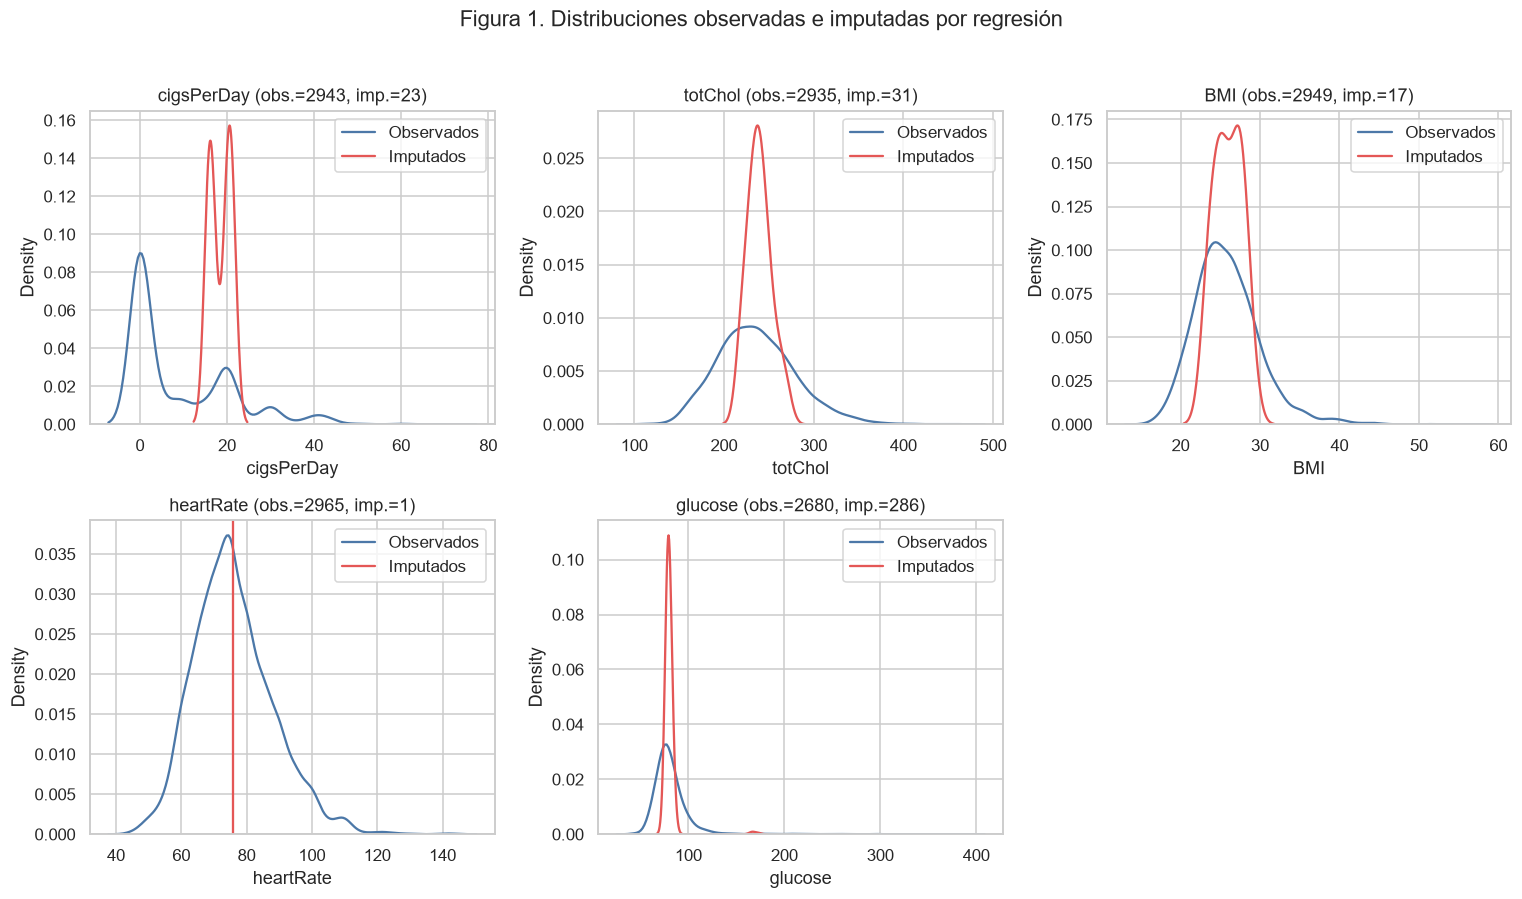

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()

for ax, variable in zip(axes, PREDICTORES_IMPUTACION):
    observados = train_original[variable].dropna()
    imputados = train_regresion.loc[train_original[variable].isna(), variable]
    sns.kdeplot(observados, ax=ax, label="Observados", color="#4C78A8")
    if len(imputados) > 1 and imputados.nunique() > 1:
        sns.kdeplot(imputados, ax=ax, label="Imputados", color="#E45756")
    else:
        ax.axvline(imputados.iloc[0] if len(imputados) else np.nan,
                   color="#E45756", label="Imputados")
    ax.set_title(f"{variable} (obs.={len(observados)}, imp.={len(imputados)})")
    ax.legend()

axes[-1].axis("off")
fig.suptitle("Figura 1. Distribuciones observadas e imputadas por regresión", y=1.02)
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "figura_1_imputacion_regresion.png", dpi=300, bbox_inches="tight")
plt.show()

### Interpretación de la imputación por regresión

El desempeño de las regresiones fue desigual. `cigsPerDay` obtuvo el mejor $R^2$ de validación cruzada (0,627), seguido por `glucose` (0,373). Para BMI (0,158), colesterol total (0,082) y frecuencia cardiaca (0,039), las variables auxiliares explicaron una fracción pequeña de la variación. Además, Breusch-Pagan y Jarque-Bera entregaron evidencia de heterocedasticidad y de residuos alejados de la normalidad. Estas pruebas son sensibles al tamaño muestral y se usan como diagnóstico, no como una condición suficiente para descartar la imputación. Por eso, la regresión se conserva como una estrategia que debe contrastarse, no como una imputación automáticamente superior.

La Figura 1 es descriptiva y compara grupos de tamaños muy distintos. La concentración de las predicciones puede reflejar tanto el encogimiento propio de una imputación determinista como el patrón de ausencia; no demuestra por sí sola calidad de imputación. Esto es especialmente importante en `heartRate`, donde la línea roja representa un único valor imputado. La regresión aporta información multivariada especialmente para cigarrillos diarios y glucosa, pero no reconstruye con precisión todas las variables.

### 1.3 Comparación de estrategias de imputación

Se comparan tres alternativas utilizando la misma partición original: eliminación de casos incompletos, imputación simple e imputación por regresión. Se revisan el tamaño disponible, la distribución de las variables imputadas y la preservación de las correlaciones con `TenYearCHD` destacadas en S1 y revisadas en S2.

In [6]:
train_eliminacion = train_original.dropna().copy()
test_eliminacion = test_original.dropna().copy()

datasets = {
    "Eliminación": (train_eliminacion, test_eliminacion),
    "Simple": (train_simple, test_simple),
    "Regresión": (train_regresion, test_regresion),
}

variables_s2 = ["age", "sysBP", "diaBP", "glucose", "totChol"]
resumen_estrategias = []
correlaciones_estrategias = []
distribuciones_estrategias = []

for nombre, (tr, te) in datasets.items():
    resumen_estrategias.append({
        "Estrategia": nombre,
        "n total disponible": len(tr) + len(te),
        "n train": len(tr),
        "n test": len(te),
        "Faltantes train": int(tr.isna().sum().sum()),
        "CHD train (%)": 100 * tr[TARGET].mean(),
    })
    for variable in variables_s2:
        correlaciones_estrategias.append({
            "Estrategia": nombre,
            "Variable": variable,
            "r con CHD (train)": tr[[variable, TARGET]].corr().iloc[0, 1],
        })
    for variable in PREDICTORES_IMPUTACION:
        distribuciones_estrategias.append({
            "Estrategia": nombre,
            "Variable": variable,
            "Media": tr[variable].mean(),
            "DE": tr[variable].std(ddof=1),
            "Mediana": tr[variable].median(),
        })

tabla_estrategias = pd.DataFrame(resumen_estrategias).set_index("Estrategia")
tabla_correlaciones = pd.DataFrame(correlaciones_estrategias).pivot(
    index="Variable", columns="Estrategia", values="r con CHD (train)"
)
tabla_distribuciones = pd.DataFrame(distribuciones_estrategias)

display(tabla_estrategias.round(3))
display(tabla_correlaciones.round(4))
display(tabla_distribuciones.pivot_table(
    index="Variable", columns="Estrategia", values=["Media", "Mediana", "DE"]
).round(3))

,n total disponible,n train,n test,Faltantes train,CHD train (%)
Estrategia,,,,,
Eliminación,3656,2539,1117,0,15.163
Simple,4238,2966,1272,0,15.206
Regresión,4238,2966,1272,0,15.206


Estrategia,Eliminación,Regresión,Simple
Variable,,,
age,0.2487,0.2404,0.2404
diaBP,0.1634,0.1542,0.1542
glucose,0.1132,0.1211,0.1158
sysBP,0.2405,0.2316,0.2316
totChol,0.1040,0.0963,0.0969


DE                         Media                     \
Estrategia Eliminación Regresión  Simple Eliminación Regresión   Simple   
Variable                                                                  
BMI              4.146     4.145   4.143      25.837    25.845   25.842   
cigsPerDay      12.033    11.934  11.929       9.035     9.022    8.879   
glucose         23.647    22.862  22.706      81.948    81.913   81.677   
heartRate       12.035    12.099  12.099      75.922    75.988   75.988   
totChol         44.040    43.556  43.536     236.849   236.372  236.305   

               Mediana                    
Estrategia Eliminación Regresión  Simple  
Variable                                  
BMI              25.41    25.410   25.41  
cigsPerDay        0.00     0.000    0.00  
glucose          78.00    78.094   78.00  
heartRate        75.00    75.000   75.00  
totChol         233.00   233.000  233.00

### Decisión sobre la estrategia principal

Esta decisión utiliza exclusivamente el conjunto de entrenamiento. La eliminación conserva 3.656 de las 4.238 filas y reduce el entrenamiento de 2.966 a 2.539 observaciones; esa pérdida de 582 registros totales podría cambiar la composición de la muestra si la ausencia no fuera MCAR. Las dos imputaciones conservan todos los casos y mantienen correlaciones muy similares.

La imputación por regresión se adopta provisionalmente porque incorpora información de otras variables, pero su ventaja sobre la imputación simple no está demostrada: varias regresiones tuvieron bajo $R^2$ y ambas estrategias preservaron relaciones semejantes. La elección se revisará mediante una comparación de sensibilidad del modelo final.

## 2. Clasificación mediante regresión logística

### 2.1 Preparación de datos informada por S1 y S2

Se utiliza inicialmente el conjunto imputado mediante regresión. Los valores extremos identificados en S1 y revisados en S2 se controlan mediante winsorización entre los percentiles 1 y 99 calculados exclusivamente con entrenamiento. Las variables continuas se estandarizan; `education` conserva su codificación ordinal de 1 a 4 y también se estandariza, mientras que las variables binarias permanecen como 0/1.

Se incorpora un término cuadrático de edad para permitir curvatura en el logit. Todos los parámetros se aprenden en entrenamiento y luego se aplican sin reajuste al conjunto de prueba.

In [7]:
CONTINUAS = ["age", "cigsPerDay", "totChol", "sysBP", "diaBP", "BMI", "heartRate", "glucose"]
BINARIAS = ["male", "currentSmoker", "BPMeds", "prevalentStroke", "prevalentHyp", "diabetes"]
ORDINALES = ["education"]
NUMERICAS_ESCALADAS = CONTINUAS + ORDINALES
PREDICTORES = NUMERICAS_ESCALADAS + BINARIAS


def ajustar_winsorizacion(train, test, columnas=CONTINUAS):
    train_w, test_w = train.copy(), test.copy()
    limites = {}
    for variable in columnas:
        inferior, superior = train[variable].quantile([0.01, 0.99])
        limites[variable] = (inferior, superior)
        train_w[variable] = train[variable].clip(inferior, superior)
        test_w[variable] = test[variable].clip(inferior, superior)
    return train_w, test_w, limites


train_modelo, test_modelo, limites_winsor = ajustar_winsorizacion(
    train_regresion, test_regresion
)

preprocesador = ColumnTransformer(
    transformers=[
        ("numericas", StandardScaler(), NUMERICAS_ESCALADAS),
        ("binarias", "passthrough", BINARIAS),
    ],
    verbose_feature_names_out=False,
)

X_train = preprocesador.fit_transform(train_modelo[PREDICTORES])
X_test = preprocesador.transform(test_modelo[PREDICTORES])
y_train = train_modelo[TARGET].astype(int).to_numpy()
y_test = test_modelo[TARGET].astype(int).to_numpy()
nombres_diseno = list(preprocesador.get_feature_names_out())

# El término cuadrático se construye a partir de la edad estandarizada.
indice_age = nombres_diseno.index("age")
X_train = np.column_stack([X_train, X_train[:, indice_age] ** 2])
X_test = np.column_stack([X_test, X_test[:, indice_age] ** 2])
nombres_diseno.append("age_cuadrado")

tabla_preparacion = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Prueba"],
    "n": [len(y_train), len(y_test)],
    "CHD (%)": [100 * y_train.mean(), 100 * y_test.mean()],
    "Predictores transformados": [X_train.shape[1], X_test.shape[1]],
})
display(tabla_preparacion.round(2))
print("Valores faltantes en X_train:", int(np.isnan(X_train).sum()))
print("Valores faltantes en X_test:", int(np.isnan(X_test).sum()))
print("Variables transformadas:", nombres_diseno)

,Conjunto,n,CHD (%),Predictores transformados
0,Entrenamiento,2966,15.21,16
1,Prueba,1272,15.17,16


Valores faltantes en X_train: 0
Valores faltantes en X_test: 0
Variables transformadas: ['age', 'cigsPerDay', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose', 'education', 'male', 'currentSmoker', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes', 'age_cuadrado']


### Interpretación de la preparación

La estratificación mantiene la frecuencia de CHD en ambos conjuntos. Después de la imputación, winsorización, estandarización y codificación no quedan valores ausentes. La prueba permanece separada y no intervino en el cálculo de medianas, modas, límites de winsorización, medias, desviaciones estándar ni selección de variables.

### 2.2 Selección de variables informada por S1 y S2

Se construyen tres modelos con criterios diferentes:

1. **Modelo S1/S2:** combina variables destacadas en S1/S2 y `prevalentHyp`, utilizada en la simulación de S2. Incluye un término cuadrático de edad para representar una posible curvatura.
2. **Modelo stepwise:** selección bidireccional basada en valores $p$, con entrada en 0,05 y salida en 0,10, usando solo entrenamiento.
3. **Modelo BIC:** eliminación hacia atrás desde el modelo completo, conservando cada reducción que disminuye el BIC.

Así se comparan un modelo guiado por resultados previos y dos procedimientos automáticos con criterios distintos.

In [8]:
def ajustar_logit(columnas, X_base=None, y_base=None):
    X_base = X_train if X_base is None else X_base
    y_base = y_train if y_base is None else y_base
    indices = [nombres_diseno.index(c) for c in columnas]
    X = sm.add_constant(X_base[:, indices], has_constant="add")
    return sm.Logit(y_base, X).fit(disp=0, maxiter=300)


def seleccion_stepwise(candidatas, X_base=None, y_base=None, entrada=0.05, salida=0.10):
    incluidas = []
    trayectoria = []
    while True:
        cambio = False
        restantes = [c for c in candidatas if c not in incluidas]
        p_entrada = {}
        for candidata in restantes:
            try:
                ajuste = ajustar_logit(incluidas + [candidata], X_base, y_base)
                p_entrada[candidata] = ajuste.pvalues[-1]
            except Exception:
                p_entrada[candidata] = np.inf
        if p_entrada:
            mejor = min(p_entrada, key=p_entrada.get)
            if p_entrada[mejor] < entrada:
                incluidas.append(mejor)
                trayectoria.append(("entra", mejor, p_entrada[mejor]))
                cambio = True

        if len(incluidas) > 1:
            ajuste = ajustar_logit(incluidas, X_base, y_base)
            pvalores = pd.Series(ajuste.pvalues[1:], index=incluidas)
            peor = pvalores.idxmax()
            if pvalores[peor] > salida:
                trayectoria.append(("sale", peor, pvalores[peor]))
                incluidas.remove(peor)
                cambio = True

        if not cambio:
            break
    return incluidas, trayectoria


def seleccion_bic(candidatas, X_base=None, y_base=None):
    actuales = list(candidatas)
    ajuste_actual = ajustar_logit(actuales, X_base, y_base)
    trayectoria = [("inicio", "modelo completo", ajuste_actual.bic)]
    while len(actuales) > 1:
        opciones = []
        for candidata in actuales:
            propuesta = [c for c in actuales if c != candidata]
            try:
                ajuste = ajustar_logit(propuesta, X_base, y_base)
                opciones.append((ajuste.bic, candidata, propuesta))
            except Exception:
                continue
        if not opciones:
            break
        mejor_bic, eliminada, propuesta = min(opciones, key=lambda x: x[0])
        if mejor_bic < ajuste_actual.bic:
            actuales = propuesta
            ajuste_actual = ajustar_logit(actuales, X_base, y_base)
            trayectoria.append(("sale", eliminada, mejor_bic))
        else:
            break
    return actuales, trayectoria


modelo_s1_s2 = ["age", "age_cuadrado", "sysBP", "diaBP", "glucose", "totChol", "prevalentHyp"]
modelo_stepwise, trayectoria_stepwise = seleccion_stepwise(nombres_diseno)
modelo_bic, trayectoria_bic = seleccion_bic(nombres_diseno)

MODELOS = {
    "M1 S1/S2": modelo_s1_s2,
    "M2 Stepwise": modelo_stepwise,
    "M3 BIC": modelo_bic,
}

tabla_variables = pd.DataFrame([
    {"Modelo": nombre, "n variables": len(columnas), "Variables": ", ".join(columnas)}
    for nombre, columnas in MODELOS.items()
]).set_index("Modelo")

display(tabla_variables)
display(pd.DataFrame(trayectoria_stepwise, columns=["Acción", "Variable", "Criterio p"]))
display(pd.DataFrame(trayectoria_bic, columns=["Acción", "Variable", "BIC"]).round(3))

,n variables,Variables
Modelo,,
M1 S1/S2,7,"age, age_cuadrado, sysBP, diaBP, glucose, totC..."
M2 Stepwise,8,"age, sysBP, cigsPerDay, glucose, male, prevale..."
M3 BIC,5,"age, cigsPerDay, sysBP, glucose, male"


,Acción,Variable,Criterio p
0,entra,age,2.280761e-36
1,entra,sysBP,1.266678e-13
2,entra,cigsPerDay,8.478512e-12
3,entra,glucose,2.302707e-04
4,entra,male,5.655072e-04
5,entra,prevalentStroke,7.265498e-03
6,entra,age_cuadrado,1.720825e-02
7,entra,BPMeds,3.519817e-02


,Acción,Variable,BIC
0,inicio,modelo completo,2344.210
1,sale,education,2336.225
2,sale,BMI,2328.313
3,sale,heartRate,2320.402
4,sale,diaBP,2312.776
5,sale,diabetes,2305.300
6,sale,currentSmoker,2298.139
7,sale,prevalentHyp,2291.491
8,sale,totChol,2286.533
9,sale,BPMeds,2282.799


In [9]:
def evaluar_clasificador(nombre, columnas):
    indices = [nombres_diseno.index(c) for c in columnas]
    Xtr, Xte = X_train[:, indices], X_test[:, indices]
    modelo = LogisticRegression(
        class_weight="balanced",
        max_iter=3000,
        random_state=SEMILLA,
    )
    modelo.fit(Xtr, y_train)
    p_tr = modelo.predict_proba(Xtr)[:, 1]
    p_te = modelo.predict_proba(Xte)[:, 1]
    pred_tr = (p_tr >= 0.5).astype(int)
    pred_te = (p_te >= 0.5).astype(int)

    filas = []
    for conjunto, y, pred, prob in (
        ("Entrenamiento", y_train, pred_tr, p_tr),
        ("Prueba", y_test, pred_te, p_te),
    ):
        tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
        filas.append({
            "Modelo": nombre,
            "Conjunto": conjunto,
            "TN": tn,
            "FP": fp,
            "FN": fn,
            "TP": tp,
            "Accuracy": accuracy_score(y, pred),
            "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred, zero_division=0),
            "F1": f1_score(y, pred, zero_division=0),
            "AUC": roc_auc_score(y, prob),
        })

    ajuste_inferencia = ajustar_logit(columnas)
    nombres_param = ["constante"] + columnas
    coeficientes = pd.DataFrame({
        "Modelo": nombre,
        "Variable": nombres_param,
        "Coeficiente": ajuste_inferencia.params,
        "OR": np.exp(ajuste_inferencia.params),
        "p": ajuste_inferencia.pvalues,
    })
    return {
        "modelo": modelo,
        "columnas": columnas,
        "indices": indices,
        "p_train": p_tr,
        "p_test": p_te,
        "pred_train": pred_tr,
        "pred_test": pred_te,
        "filas": filas,
        "coeficientes": coeficientes,
        "ajuste_inferencia": ajuste_inferencia,
    }


resultados_modelos = {
    nombre: evaluar_clasificador(nombre, columnas)
    for nombre, columnas in MODELOS.items()
}


def evaluar_receta_cv(nombre, columnas_fijas=None):
    """Repite la selección de variables dentro de cada pliegue de entrenamiento."""
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
    aucs, cantidades = [], []
    for idx_tr, idx_val in cv.split(X_train, y_train):
        Xtr_fold, Xval_fold = X_train[idx_tr], X_train[idx_val]
        ytr_fold, yval_fold = y_train[idx_tr], y_train[idx_val]

        if nombre == "M1 S1/S2":
            columnas = list(columnas_fijas)
        elif nombre == "M2 Stepwise":
            columnas, _ = seleccion_stepwise(
                nombres_diseno, Xtr_fold, ytr_fold
            )
        else:
            columnas, _ = seleccion_bic(
                nombres_diseno, Xtr_fold, ytr_fold
            )

        indices = [nombres_diseno.index(c) for c in columnas]
        modelo_fold = LogisticRegression(
            class_weight="balanced", max_iter=3000, random_state=SEMILLA
        ).fit(Xtr_fold[:, indices], ytr_fold)
        prob = modelo_fold.predict_proba(Xval_fold[:, indices])[:, 1]
        aucs.append(roc_auc_score(yval_fold, prob))
        cantidades.append(len(columnas))

    return np.asarray(aucs), cantidades


resultados_cv = {}
for nombre, columnas in MODELOS.items():
    aucs, cantidades = evaluar_receta_cv(nombre, columnas)
    resultados_cv[nombre] = {
        "aucs": aucs,
        "cantidad_media": np.mean(cantidades),
    }

tabla_desempeno = pd.DataFrame([
    fila
    for resultado in resultados_modelos.values()
    for fila in resultado["filas"]
])

tabla_cv = pd.DataFrame([
    {
        "Modelo": nombre,
        "Variables": len(resultado["columnas"]),
        "CV AUC media": resultados_cv[nombre]["aucs"].mean(),
        "CV AUC DE": resultados_cv[nombre]["aucs"].std(ddof=1),
        "Variables medias por pliegue": resultados_cv[nombre]["cantidad_media"],
    }
    for nombre, resultado in resultados_modelos.items()
]).set_index("Modelo")

tabla_coeficientes = pd.concat(
    [r["coeficientes"] for r in resultados_modelos.values()], ignore_index=True
)

display(tabla_cv.round(4))
display(tabla_desempeno.set_index(["Modelo", "Conjunto"]).round(4))
display(tabla_coeficientes.round(4))

,Variables,CV AUC media,CV AUC DE,Variables medias por pliegue
Modelo,,,,
M1 S1/S2,7,0.7197,0.0167,7.0
M2 Stepwise,8,0.7346,0.0250,6.8
M3 BIC,5,0.7336,0.0295,5.0


TN   FP   FN   TP  Accuracy  Precision  Recall  \
Modelo      Conjunto                                                          
M1 S1/S2    Entrenamiento  1595  920  138  313    0.6433     0.2539  0.6940   
            Prueba          677  402   70  123    0.6289     0.2343  0.6373   
M2 Stepwise Entrenamiento  1664  851  139  312    0.6662     0.2683  0.6918   
            Prueba          708  371   73  120    0.6509     0.2444  0.6218   
M3 BIC      Entrenamiento  1695  820  136  315    0.6777     0.2775  0.6984   
            Prueba          727  352   77  116    0.6627     0.2479  0.6010   

                               F1     AUC  
Modelo      Conjunto                       
M1 S1/S2    Entrenamiento  0.3717  0.7234  
            Prueba         0.3426  0.6728  
M2 Stepwise Entrenamiento  0.3866  0.7451  
            Prueba         0.3509  0.6953  
M3 BIC      Entrenamiento  0.3972  0.7387  
            Prueba         0.3510  0.7026

,Modelo,Variable,Coeficiente,OR,p
0,M1 S1/S2,constante,-1.8992,0.1497,0.0000
1,M1 S1/S2,age,0.6046,1.8305,0.0000
2,M1 S1/S2,age_cuadrado,-0.1415,0.8681,0.0221
3,M1 S1/S2,sysBP,0.2756,1.3174,0.0026
4,M1 S1/S2,diaBP,0.0017,1.0017,0.9836
5,M1 S1/S2,glucose,0.1585,1.1717,0.0006
6,M1 S1/S2,totChol,0.0604,1.0622,0.2720
7,M1 S1/S2,prevalentHyp,0.2526,1.2873,0.1004
8,M2 Stepwise,constante,-2.0808,0.1248,0.0000
9,M2 Stepwise,age,0.7071,2.0280,0.0000


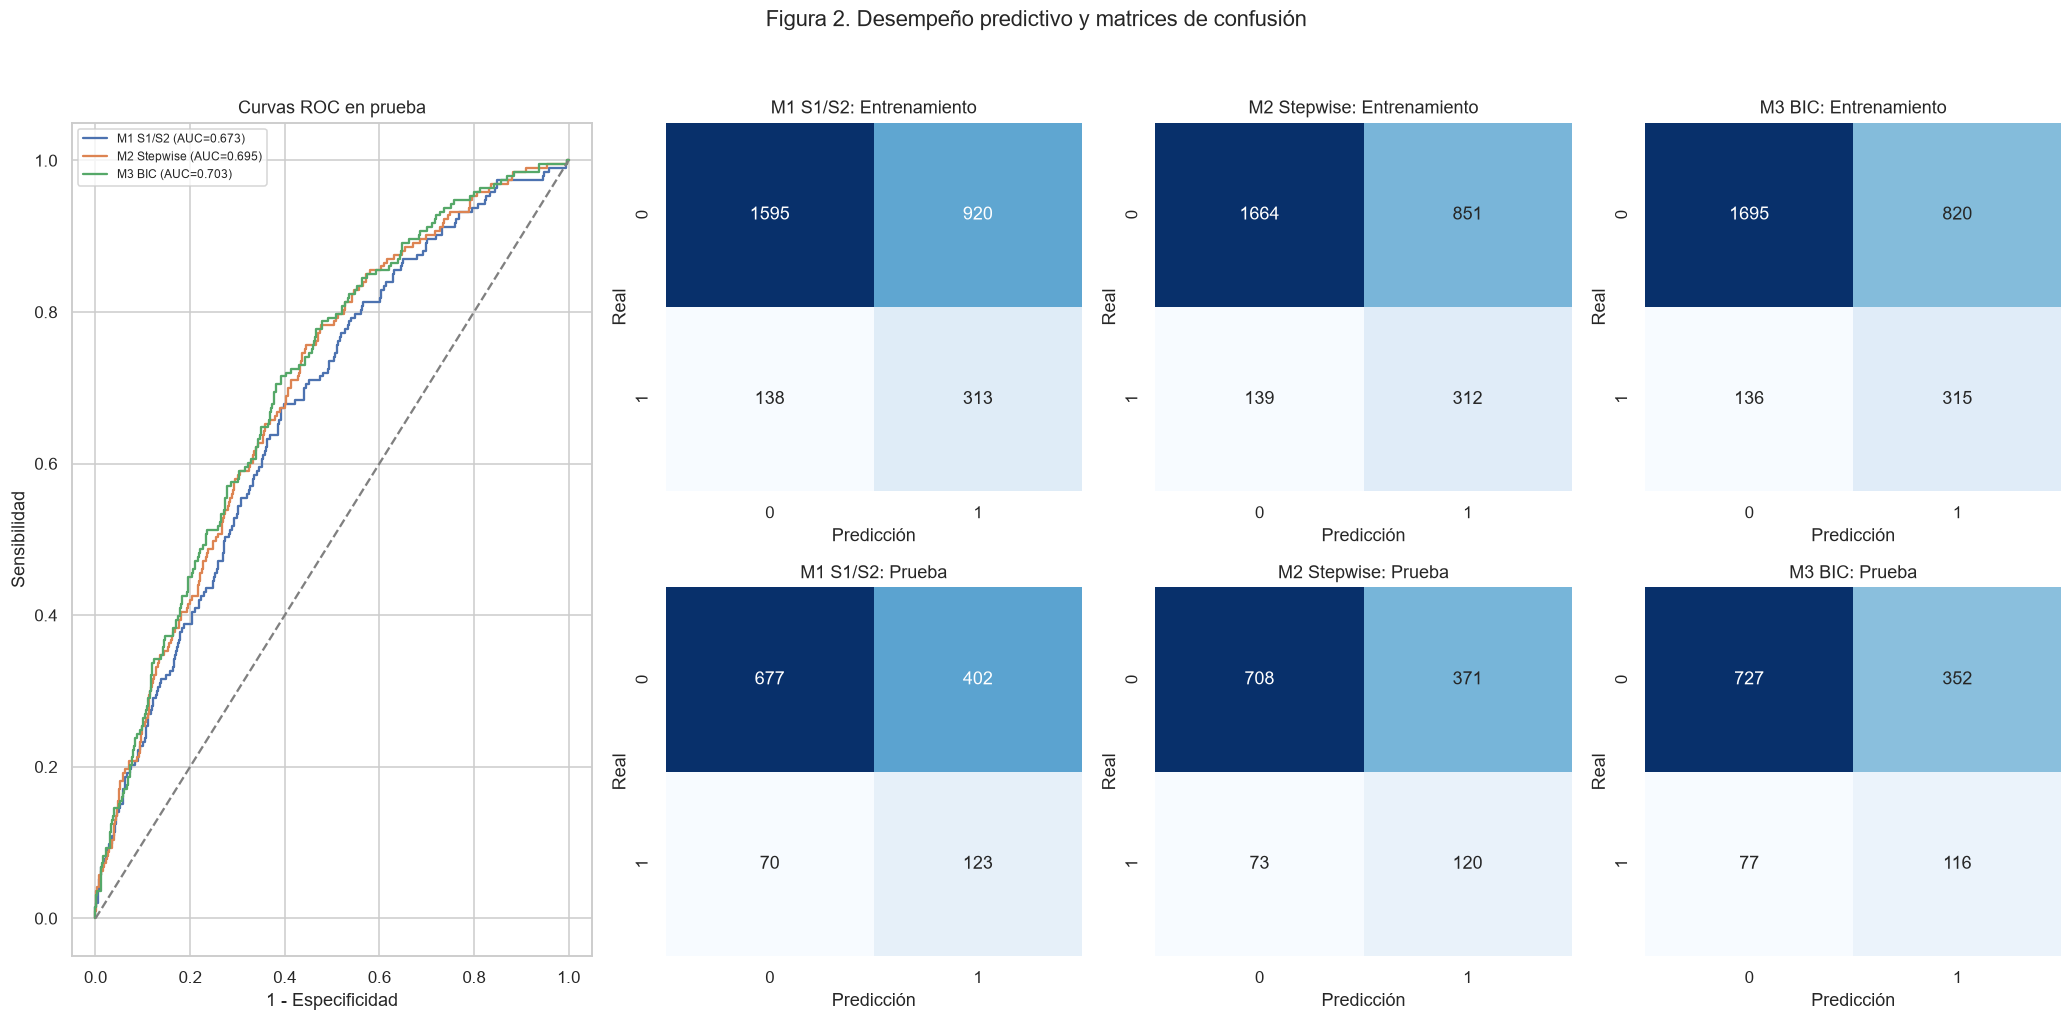

Modelo seleccionado mediante CV AUC: M3 BIC
Mejor AUC CV: M2 Stepwise
Umbral de la regla de un error estándar: 0.7234


,TN,FP,FN,TP,Accuracy,Precision,Recall,F1,AUC
Modelo,,,,,,,,,
M1 S1/S2,677,402,70,123,0.6289,0.2343,0.6373,0.3426,0.6728
M2 Stepwise,708,371,73,120,0.6509,0.2444,0.6218,0.3509,0.6953
M3 BIC,727,352,77,116,0.6627,0.2479,0.6010,0.3510,0.7026


In [10]:
# La selección se realiza solo con entrenamiento. Se aplica la regla de un error
# estándar: entre los modelos compatibles con el mejor AUC, se prefiere el más simple.
modelo_auc_maximo = tabla_cv["CV AUC media"].idxmax()
umbral_un_se = (
    tabla_cv.loc[modelo_auc_maximo, "CV AUC media"]
    - tabla_cv.loc[modelo_auc_maximo, "CV AUC DE"] / np.sqrt(5)
)
candidatos_un_se = tabla_cv.query("`CV AUC media` >= @umbral_un_se").copy()
MEJOR_MODELO = candidatos_un_se.sort_values(
    ["Variables", "CV AUC media"], ascending=[True, False]
).index[0]
mejor = resultados_modelos[MEJOR_MODELO]

fig = plt.figure(figsize=(19, 9))
rejilla = fig.add_gridspec(2, 4, width_ratios=[1.25, 1, 1, 1])
ax_roc = fig.add_subplot(rejilla[:, 0])
for nombre, resultado in resultados_modelos.items():
    fpr, tpr, _ = roc_curve(y_test, resultado["p_test"])
    auc = roc_auc_score(y_test, resultado["p_test"])
    ax_roc.plot(fpr, tpr, label=f"{nombre} (AUC={auc:.3f})")
ax_roc.plot([0, 1], [0, 1], "--", color="gray")
ax_roc.set(title="Curvas ROC en prueba", xlabel="1 - Especificidad", ylabel="Sensibilidad")
ax_roc.legend(fontsize=8)

for columna, (nombre, resultado) in enumerate(resultados_modelos.items(), start=1):
    for fila, (y, pred, conjunto) in enumerate((
        (y_train, resultado["pred_train"], "Entrenamiento"),
        (y_test, resultado["pred_test"], "Prueba"),
    )):
        ax = fig.add_subplot(rejilla[fila, columna])
        matriz = confusion_matrix(y, pred)
        sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
        ax.set(title=f"{nombre}: {conjunto}", xlabel="Predicción", ylabel="Real")

fig.suptitle("Figura 2. Desempeño predictivo y matrices de confusión", y=1.03)
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "figura_2_desempeno_modelos.png", dpi=300, bbox_inches="tight")
plt.show()

print("Modelo seleccionado mediante CV AUC:", MEJOR_MODELO)
print(f"Mejor AUC CV: {modelo_auc_maximo}")
print(f"Umbral de la regla de un error estándar: {umbral_un_se:.4f}")
display(
    tabla_desempeno.query("Conjunto == 'Prueba'")
    .set_index("Modelo")[["TN", "FP", "FN", "TP", "Accuracy", "Precision", "Recall", "F1", "AUC"]]
    .round(4)
)

### Interpretación de la selección y el desempeño

La comparación utiliza validación cruzada dentro de entrenamiento para seleccionar el modelo, mientras que el conjunto de prueba se reserva para comprobar su desempeño fuera de muestra. En cada pliegue se repite la selección stepwise o BIC; no obstante, la imputación, winsorización y estandarización ya fueron ajustadas sobre todo el entrenamiento, por lo que esta es una validación interna de la selección y no una tubería completamente anidada. Se aplica la regla de un error estándar para privilegiar parsimonia cuando las diferencias de AUC son pequeñas.

Debido al desbalance de `TenYearCHD`, la exactitud no se interpreta de manera aislada: se consideran conjuntamente *recall*, precisión, F1 y AUC. La ponderación de clases favorece la detección de personas con CHD, aunque puede aumentar los falsos positivos. Las probabilidades producidas por ese clasificador ponderado se emplean como puntajes para discriminación; no se interpretan como riesgos clínicos calibrados.

M2 obtuvo el mayor AUC medio en validación cruzada (0,7346), pero M3 quedó prácticamente empatado (0,7336) y utilizó solo cinco variables. La regla de un error estándar seleccionó M3 BIC: edad, cigarrillos diarios, presión sistólica, glucosa y sexo. En prueba alcanzó AUC 0,7026, *recall* 0,6010 y F1 0,3510. La matriz registró 116 verdaderos positivos, 77 falsos negativos, 727 verdaderos negativos y 352 falsos positivos. Esto representa una discriminación moderada: mejora al azar, pero todavía comete errores relevantes.

Los coeficientes y *odds ratios* se obtienen mediante máxima verosimilitud sin ponderación de clases para conservar una interpretación inferencial estándar. Las matrices de confusión, en cambio, corresponden al clasificador ponderado usado para predicción.

### 2.3 Evaluación de estabilidad mediante bootstrap

Se aplican 1.000 remuestras bootstrap a las filas del conjunto de entrenamiento y se reajusta el modelo seleccionado en cada una. Se construyen intervalos percentil del 95 % para coeficientes y *odds ratios* y se comparan con los intervalos tradicionales de Wald. El conjunto de prueba no participa en este procedimiento.

,Variable,Coeficiente,Wald inferior,Wald superior,Bootstrap inferior,Bootstrap superior,OR,OR Wald inferior,OR Wald superior,OR bootstrap inferior,OR bootstrap superior,Estable
0,constante,-2.1716,-2.3409,-2.0023,-2.3718,-2.0155,0.1140,0.0962,0.1350,0.0933,0.1333,True
1,age,0.6128,0.4920,0.7336,0.5049,0.7307,1.8456,1.6356,2.0825,1.6569,2.0765,True
2,cigsPerDay,0.2991,0.1904,0.4079,0.1941,0.4029,1.3487,1.2097,1.5036,1.2142,1.4961,True
3,sysBP,0.4000,0.2953,0.5046,0.2901,0.5111,1.4918,1.3436,1.6563,1.3365,1.6672,True
4,glucose,0.1644,0.0742,0.2547,0.0694,0.2588,1.1787,1.0770,1.2901,1.0719,1.2954,True
5,male,0.4042,0.1744,0.6340,0.1730,0.6355,1.4981,1.1905,1.8851,1.1889,1.8879,True


Remuestras solicitadas: 1000
Remuestras válidas: 1000
Fallos de convergencia: 0


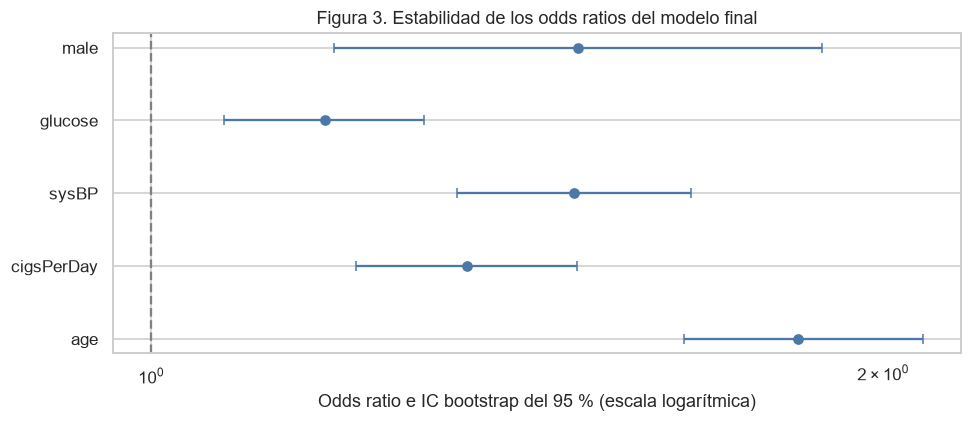

In [11]:
columnas_mejor = mejor["columnas"]
indices_mejor = mejor["indices"]
Xtr_mejor = X_train[:, indices_mejor]

ajuste_wald = mejor["ajuste_inferencia"]
parametros_wald = np.asarray(ajuste_wald.params)
ic_wald = np.asarray(ajuste_wald.conf_int(alpha=0.05))

n_bootstrap = 1000
coefs_bootstrap = []
fallos_bootstrap = 0

for _ in range(n_bootstrap):
    idx = rng.integers(0, len(y_train), len(y_train))
    Xb, yb = Xtr_mejor[idx], y_train[idx]
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("error", ConvergenceWarning)
            modelo_b = LogisticRegression(
                penalty=None,
                solver="lbfgs",
                max_iter=2000,
                random_state=SEMILLA,
            )
            modelo_b.fit(Xb, yb)
        coefs_bootstrap.append(np.r_[modelo_b.intercept_[0], modelo_b.coef_[0]])
    except Exception:
        fallos_bootstrap += 1

coefs_bootstrap = np.asarray(coefs_bootstrap)
ic_boot = np.percentile(coefs_bootstrap, [2.5, 97.5], axis=0).T
nombres_parametros = ["constante"] + columnas_mejor

tabla_bootstrap = pd.DataFrame({
    "Variable": nombres_parametros,
    "Coeficiente": parametros_wald,
    "Wald inferior": ic_wald[:, 0],
    "Wald superior": ic_wald[:, 1],
    "Bootstrap inferior": ic_boot[:, 0],
    "Bootstrap superior": ic_boot[:, 1],
})
tabla_bootstrap["OR"] = np.exp(tabla_bootstrap["Coeficiente"])
tabla_bootstrap["OR Wald inferior"] = np.exp(tabla_bootstrap["Wald inferior"])
tabla_bootstrap["OR Wald superior"] = np.exp(tabla_bootstrap["Wald superior"])
tabla_bootstrap["OR bootstrap inferior"] = np.exp(tabla_bootstrap["Bootstrap inferior"])
tabla_bootstrap["OR bootstrap superior"] = np.exp(tabla_bootstrap["Bootstrap superior"])
tabla_bootstrap["Estable"] = ~(
    (tabla_bootstrap["Bootstrap inferior"] <= 0)
    & (tabla_bootstrap["Bootstrap superior"] >= 0)
)

display(tabla_bootstrap.round(4))
print(f"Remuestras solicitadas: {n_bootstrap}")
print(f"Remuestras válidas: {len(coefs_bootstrap)}")
print(f"Fallos de convergencia: {fallos_bootstrap}")

fig, ax = plt.subplots(figsize=(9, max(4, 0.45 * len(columnas_mejor))))
grafico_or = tabla_bootstrap.query("Variable != 'constante'").copy()
y_pos = np.arange(len(grafico_or))
ax.errorbar(
    grafico_or["OR"],
    y_pos,
    xerr=[
        grafico_or["OR"] - grafico_or["OR bootstrap inferior"],
        grafico_or["OR bootstrap superior"] - grafico_or["OR"],
    ],
    fmt="o",
    color="#4C78A8",
    capsize=3,
)
ax.axvline(1, linestyle="--", color="gray")
ax.set_xscale("log")
ax.set_yticks(y_pos, grafico_or["Variable"])
ax.set_xlabel("Odds ratio e IC bootstrap del 95 % (escala logarítmica)")
ax.set_title("Figura 3. Estabilidad de los odds ratios del modelo final")
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "figura_3_bootstrap_odds_ratios.png", dpi=300, bbox_inches="tight")
plt.show()

### Interpretación del bootstrap

Las 1.000 remuestras convergieron. Los cinco predictores mantuvieron intervalos bootstrap de *odds ratio* por encima de uno: edad 1,66–2,08; cigarrillos diarios 1,21–1,50; presión sistólica 1,34–1,67; glucosa 1,07–1,30; y sexo masculino 1,19–1,89. Como las variables continuas fueron estandarizadas, esos *odds ratios* representan el cambio asociado a una desviación estándar y no a una unidad original. Los intervalos bootstrap fueron cercanos a los de Wald, lo que apoya estabilidad interna de los signos y magnitudes.

Este bootstrap es condicional: mantiene fijas la imputación, la transformación de variables y la selección del modelo; por ello no incorpora toda la incertidumbre del flujo completo ni constituye validación externa.

### 2.4 Diagnóstico de supuestos

El modelo final se revisa mediante VIF, linealidad aproximada en el logit, residuos de Pearson y distancia de Cook. Los diagnósticos no prueban que el modelo sea verdadero; permiten identificar señales de especificación deficiente, multicolinealidad u observaciones con influencia desproporcionada.

,Variable,VIF
0,age,1.239
2,sysBP,1.207
1,cigsPerDay,1.168
4,male,1.123
3,glucose,1.030


,Variable,p Box-Tidwell
0,age,0.0154
1,cigsPerDay,0.8811
2,sysBP,0.2889
3,glucose,0.0636


,Índice original,Cook,Residuo Pearson,Probabilidad ajustada,CHD observado
2410,247,0.0101,2.8584,0.1090,1
2365,1649,0.0088,2.1424,0.1789,1
1560,2893,0.0069,1.4615,0.3189,1
1600,1674,0.0068,1.6102,0.2783,1
247,2234,0.0067,1.7025,0.2565,1
2512,3868,0.0064,1.6130,0.2776,1
2082,4096,0.0061,1.6169,0.2767,1
1750,3971,0.0059,-1.4697,0.6835,0
791,965,0.0058,1.6580,0.2667,1
2824,3680,0.0057,1.3861,0.3423,1


,Variable,Coeficiente principal,Coeficiente sensibilidad,OR principal,OR sensibilidad
0,constante,-2.1716,-3.6043,0.1140,0.0272
1,age,0.6128,1.0970,1.8456,2.9952
2,cigsPerDay,0.2991,0.3542,1.3487,1.4250
3,sysBP,0.4000,0.7107,1.4918,2.0354
4,glucose,0.1644,0.1827,1.1787,1.2004
5,male,0.4042,0.6374,1.4981,1.8916


VIF máximo: 1.239
Observaciones con Cook > 4/n: 261 (8.80 %)
Residuos de Pearson |r| > 3: 81 (2.73 %)


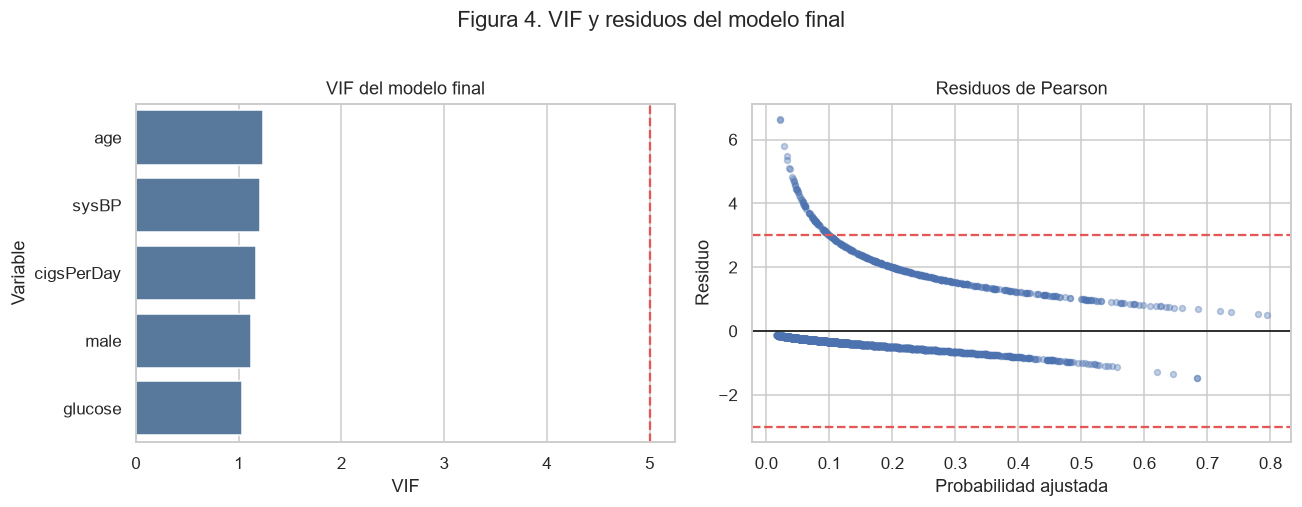

In [12]:
X_diag = pd.DataFrame(Xtr_mejor, columns=columnas_mejor)
X_vif = sm.add_constant(X_diag, has_constant="add")
tabla_vif = pd.DataFrame({
    "Variable": columnas_mejor,
    "VIF": [
        variance_inflation_factor(X_vif.values, i + 1)
        for i in range(X_diag.shape[1])
    ],
}).sort_values("VIF", ascending=False)

X_const = sm.add_constant(Xtr_mejor, has_constant="add")
ajuste_glm = sm.GLM(y_train, X_const, family=sm.families.Binomial()).fit()
influencia = ajuste_glm.get_influence()
cook = influencia.cooks_distance[0]
residuos_pearson = ajuste_glm.resid_pearson
umbral_cook = 4 / len(y_train)

# Box-Tidwell aproximado en variables continuas originales incluidas.
continuas_mejor = [c for c in columnas_mejor if c in CONTINUAS]
resultados_linealidad = []
base_bt = train_modelo.copy()
for variable in continuas_mejor:
    minimo = base_bt[variable].min()
    desplazada = base_bt[variable] - minimo + 1e-6
    X_bt = Xtr_mejor.copy()
    termino = desplazada.to_numpy() * np.log(desplazada.to_numpy())
    X_ampliada = np.column_stack([X_bt, termino])
    try:
        ajuste_bt = sm.Logit(
            y_train, sm.add_constant(X_ampliada, has_constant="add")
        ).fit(disp=0, maxiter=300)
        p_bt = ajuste_bt.pvalues[-1]
    except Exception:
        p_bt = np.nan
    resultados_linealidad.append({"Variable": variable, "p Box-Tidwell": p_bt})

tabla_linealidad = pd.DataFrame(resultados_linealidad)

# Revisión de influencia: se reportan los casos más influyentes y un ajuste de
# sensibilidad sin observaciones que superan 4/n. No implica eliminarlas del análisis.
tabla_influencia = pd.DataFrame({
    "Índice original": train_modelo.index,
    "Cook": cook,
    "Residuo Pearson": residuos_pearson,
    "Probabilidad ajustada": ajuste_glm.fittedvalues,
    "CHD observado": y_train,
}).sort_values("Cook", ascending=False)

mascara_sensibilidad = cook <= umbral_cook
ajuste_sensibilidad = sm.Logit(
    y_train[mascara_sensibilidad],
    sm.add_constant(Xtr_mejor[mascara_sensibilidad], has_constant="add"),
).fit(disp=0, maxiter=300)
tabla_sensibilidad = pd.DataFrame({
    "Variable": ["constante"] + columnas_mejor,
    "Coeficiente principal": ajuste_wald.params,
    "Coeficiente sensibilidad": ajuste_sensibilidad.params,
    "OR principal": np.exp(ajuste_wald.params),
    "OR sensibilidad": np.exp(ajuste_sensibilidad.params),
})

display(tabla_vif.round(3))
display(tabla_linealidad.round(4))
display(tabla_influencia.head(10).round(4))
display(tabla_sensibilidad.round(4))
print(f"VIF máximo: {tabla_vif['VIF'].max():.3f}")
print(f"Observaciones con Cook > 4/n: {(cook > umbral_cook).sum()} ({100*(cook > umbral_cook).mean():.2f} %)")
print(f"Residuos de Pearson |r| > 3: {(np.abs(residuos_pearson) > 3).sum()} ({100*(np.abs(residuos_pearson) > 3).mean():.2f} %)")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(data=tabla_vif, x="VIF", y="Variable", color="#4C78A8", ax=axes[0])
axes[0].axvline(5, linestyle="--", color="#E45756")
axes[0].set_title("VIF del modelo final")

axes[1].scatter(ajuste_glm.fittedvalues, residuos_pearson, alpha=0.35, s=15)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].axhline(3, linestyle="--", color="#E45756")
axes[1].axhline(-3, linestyle="--", color="#E45756")
axes[1].set(title="Residuos de Pearson", xlabel="Probabilidad ajustada", ylabel="Residuo")

fig.suptitle("Figura 4. VIF y residuos del modelo final", y=1.02)
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "figura_4_diagnosticos_modelo.png", dpi=300, bbox_inches="tight")
plt.show()

### Interpretación de los diagnósticos

El VIF máximo fue 1,239, muy inferior al umbral práctico de 5; no se observa multicolinealidad preocupante. Box-Tidwell no detectó una señal clara para cigarrillos diarios ni presión sistólica, pero sí para edad ($p=0,0154$) y una señal limítrofe para glucosa ($p=0,0636$). Por ello, la linealidad en el logit no queda completamente satisfecha y en una extensión convendría evaluar términos no lineales o *splines*.

Se identificaron 261 observaciones sobre el umbral de Cook $4/n$ (8,80 %) y 81 residuos de Pearson con valor absoluto mayor que 3 (2,73 %). Al excluir esos casos solo como análisis de sensibilidad, todos los coeficientes conservaron signo positivo, pero sus magnitudes aumentaron, especialmente edad y presión sistólica. El ajuste fue sensible al conjunto señalado por el criterio $4/n$; como se trata de 8,80 % del entrenamiento, esto no justifica borrar casos automáticamente y obliga a interpretar los *odds ratios* con cautela.

## 3. Sensibilidad a la estrategia de imputación

El modelo final se reajusta con eliminación, imputación simple e imputación por regresión. Cada estrategia utiliza los mismos índices originales de entrenamiento y prueba; sus imputadores, límites de winsorización y escaladores se ajustan de forma independiente solo con entrenamiento. Se mantiene el mismo conjunto de variables del modelo seleccionado para que las diferencias puedan atribuirse al tratamiento de faltantes.

,n train,n test,Accuracy test,Precision test,Recall test,F1 test,AUC test
Estrategia,,,,,,,
Eliminación,2539,1117,0.6732,0.2629,0.6221,0.3696,0.7073
Simple,2966,1117,0.6625,0.2530,0.6105,0.3578,0.7059
Regresión,2966,1117,0.6670,0.2549,0.6047,0.3586,0.7059


,Estrategia,Variable,Coeficiente,IC inferior,IC superior
0,Eliminación,constante,-2.2286,-2.4182,-2.0391
1,Eliminación,age,0.6321,0.5011,0.7631
2,Eliminación,cigsPerDay,0.2918,0.1733,0.4102
3,Eliminación,sysBP,0.4313,0.3184,0.5443
4,Eliminación,glucose,0.1512,0.0533,0.2491
5,Eliminación,male,0.4625,0.2108,0.7143
6,Simple,constante,-2.1682,-2.3373,-1.9991
7,Simple,age,0.6117,0.4911,0.7323
8,Simple,cigsPerDay,0.3028,0.1944,0.4112
9,Simple,sysBP,0.4034,0.2989,0.5079


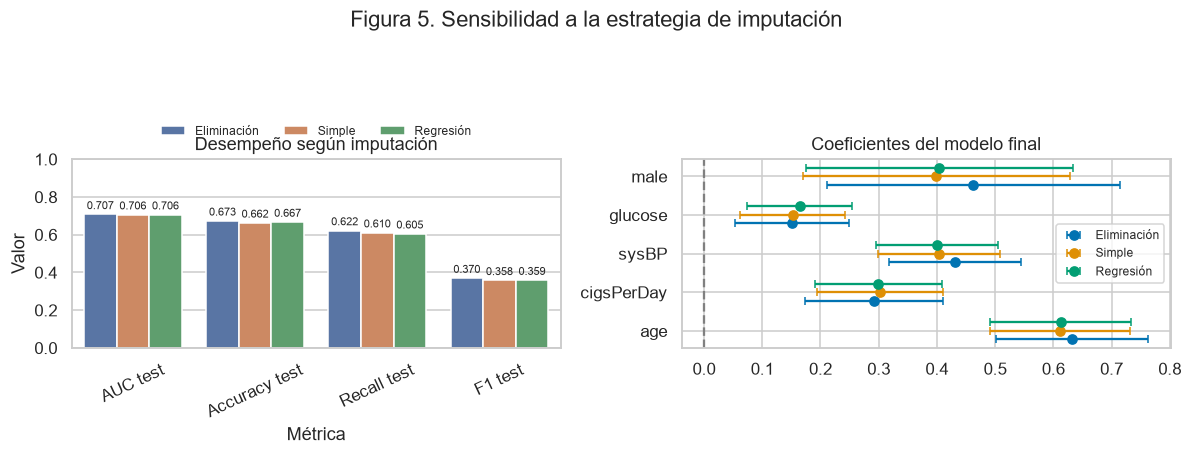

In [13]:
def preparar_estrategia(train, test):
    tr_w, te_w, _ = ajustar_winsorizacion(train, test)
    prep = ColumnTransformer(
        transformers=[
            ("numericas", StandardScaler(), NUMERICAS_ESCALADAS),
            ("binarias", "passthrough", BINARIAS),
        ],
        verbose_feature_names_out=False,
    )
    Xtr = prep.fit_transform(tr_w[PREDICTORES])
    Xte = prep.transform(te_w[PREDICTORES])
    nombres = list(prep.get_feature_names_out())
    indice_age = nombres.index("age")
    Xtr = np.column_stack([Xtr, Xtr[:, indice_age] ** 2])
    Xte = np.column_stack([Xte, Xte[:, indice_age] ** 2])
    nombres.append("age_cuadrado")
    indices = [nombres.index(c) for c in columnas_mejor]
    return Xtr[:, indices], Xte[:, indices], tr_w[TARGET].to_numpy(), te_w[TARGET].to_numpy()


comparacion_imputacion = []
coeficientes_imputacion = []
indices_test_comunes = sorted(
    set.intersection(*[set(te.index) for _, te in datasets.values()])
)
for nombre, (tr, te) in datasets.items():
    te_comun = te.loc[indices_test_comunes].copy()
    Xtr, Xte, ytr, yte = preparar_estrategia(tr, te_comun)
    clasificador = LogisticRegression(
        class_weight="balanced", max_iter=3000, random_state=SEMILLA
    ).fit(Xtr, ytr)
    prob = clasificador.predict_proba(Xte)[:, 1]
    pred = (prob >= 0.5).astype(int)

    ajuste = sm.Logit(ytr, sm.add_constant(Xtr, has_constant="add")).fit(
        disp=0, maxiter=300
    )
    ic = np.asarray(ajuste.conf_int())
    comparacion_imputacion.append({
        "Estrategia": nombre,
        "n train": len(ytr),
        "n test": len(yte),
        "Accuracy test": accuracy_score(yte, pred),
        "Precision test": precision_score(yte, pred, zero_division=0),
        "Recall test": recall_score(yte, pred, zero_division=0),
        "F1 test": f1_score(yte, pred, zero_division=0),
        "AUC test": roc_auc_score(yte, prob),
    })
    for i, variable in enumerate(["constante"] + columnas_mejor):
        coeficientes_imputacion.append({
            "Estrategia": nombre,
            "Variable": variable,
            "Coeficiente": ajuste.params[i],
            "IC inferior": ic[i, 0],
            "IC superior": ic[i, 1],
        })

tabla_impacto = pd.DataFrame(comparacion_imputacion).set_index("Estrategia")
tabla_coef_imputacion = pd.DataFrame(coeficientes_imputacion)
display(tabla_impacto.round(4))
display(tabla_coef_imputacion.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
metricas_grafico = tabla_impacto.reset_index().melt(
    id_vars="Estrategia",
    value_vars=["AUC test", "Accuracy test", "Recall test", "F1 test"],
    var_name="Métrica",
    value_name="Valor",
)
sns.barplot(data=metricas_grafico, x="Métrica", y="Valor", hue="Estrategia", ax=axes[0])
axes[0].set_ylim(0, 1)
axes[0].set_title("Desempeño según imputación")
axes[0].tick_params(axis="x", rotation=25)
for contenedor in axes[0].containers:
    axes[0].bar_label(contenedor, fmt="%.3f", fontsize=7, padding=2)
axes[0].legend(
    loc="upper center", bbox_to_anchor=(0.5, 1.24), ncol=3,
    fontsize=8, title=None, frameon=False,
)

coef_plot = tabla_coef_imputacion.query("Variable != 'constante'").copy()
variables_plot = list(dict.fromkeys(coef_plot["Variable"]))
estrategias_plot = list(tabla_impacto.index)
colores = sns.color_palette("colorblind", n_colors=len(estrategias_plot))
desplazamientos = np.linspace(-0.22, 0.22, len(estrategias_plot))
for desplazamiento, estrategia, color in zip(desplazamientos, estrategias_plot, colores):
    sub = coef_plot.query("Estrategia == @estrategia").set_index("Variable").loc[variables_plot]
    posiciones = np.arange(len(variables_plot)) + desplazamiento
    axes[1].errorbar(
        sub["Coeficiente"], posiciones,
        xerr=[sub["Coeficiente"] - sub["IC inferior"], sub["IC superior"] - sub["Coeficiente"]],
        fmt="o", capsize=2.5, color=color, label=estrategia,
    )
axes[1].axvline(0, linestyle="--", color="gray")
axes[1].set_yticks(np.arange(len(variables_plot)), variables_plot)
axes[1].legend(fontsize=8)
axes[1].set_title("Coeficientes del modelo final")

fig.suptitle("Figura 5. Sensibilidad a la estrategia de imputación", y=1.03)
plt.tight_layout()
plt.savefig(DIR_FIGURAS / "figura_5_impacto_imputacion.png", dpi=300, bbox_inches="tight")
plt.show()

### Interpretación de la sensibilidad a la imputación

Las tres estrategias se evaluaron sobre las mismas 1.117 observaciones completas de prueba. Los AUC fueron muy similares: 0,7073 con eliminación y 0,7059 tanto con imputación simple como con regresión. Los intervalos de los coeficientes se superpusieron y todos conservaron la misma dirección. La eliminación obtuvo una ventaja mínima, pero redujo el entrenamiento de 2.966 a 2.539 filas; esa diferencia de 0,0014 en AUC no muestra una ventaja predictiva clara frente a conservar 427 observaciones adicionales.

En consecuencia, las conclusiones principales son poco sensibles a la estrategia de faltantes en esta partición. La imputación por regresión permite conservar la muestra completa, aunque sus diagnósticos débiles para varias variables deben declararse como limitación; la imputación simple constituye una alternativa casi equivalente en desempeño. Como el conjunto común contiene únicamente casos completos, esta comparación mide principalmente el efecto de la estrategia aplicada en entrenamiento y no evalúa directamente el desempeño sobre nuevas observaciones con valores faltantes.

## 4. Síntesis integrada y preparación de entregables

S1 describió la muestra y detectó faltantes, valores extremos y asociaciones bivariadas. S2 mostró que varias asociaciones eran internamente estables, aunque débiles, y recomendó controlar extremos y faltantes dentro de entrenamiento. S3 convierte esos antecedentes en un flujo predictivo: compara imputaciones, selecciona variables con tres criterios, evalúa el desempeño fuera de muestra, revisa diagnósticos y utiliza bootstrap para cuantificar la estabilidad de los parámetros.

El resultado central es M3 BIC, un modelo parsimonioso con edad, cigarrillos diarios, presión sistólica, glucosa y sexo. Su AUC de prueba fue 0,7026 y los cinco parámetros conservaron signo positivo en el bootstrap. Sin embargo, la precisión fue 0,2479 y quedaron 77 casos positivos sin detectar al umbral 0,5. Además, el diagnóstico sugirió no linealidad para edad e influencia apreciable de varias observaciones. Por tanto, el modelo sirve como ejercicio de discriminación y comparación metodológica, pero no está listo para decisiones clínicas.

La interpretación final debe mantenerse en el plano predictivo y asociativo. El modelo no demuestra causalidad ni reemplaza una validación externa, una evaluación clínica o una revisión de calibración. Su utilidad consiste en distinguir, con capacidad moderada, entre personas que desarrollaron y no desarrollaron CHD a diez años dentro de esta base, y en mostrar qué decisiones metodológicas modifican o conservan las conclusiones.

In [14]:
tabla_desempeno.to_csv(DIR_RESULTADOS / "desempeno_tres_modelos.csv", index=False)
tabla_cv.to_csv(DIR_RESULTADOS / "validacion_cruzada_modelos.csv")
tabla_bootstrap.to_csv(DIR_RESULTADOS / "intervalos_bootstrap_modelo_final.csv", index=False)
tabla_impacto.to_csv(DIR_RESULTADOS / "impacto_estrategias_imputacion.csv")
tabla_coef_imputacion.to_csv(DIR_RESULTADOS / "coeficientes_por_imputacion.csv", index=False)
evaluacion_imputacion.to_csv(DIR_RESULTADOS / "desempeno_regresiones_imputacion.csv", index=False)
diagnosticos_imputacion.to_csv(DIR_RESULTADOS / "diagnosticos_regresiones_imputacion.csv", index=False)
tabla_vif.to_csv(DIR_RESULTADOS / "vif_modelo_final.csv", index=False)
tabla_linealidad.to_csv(DIR_RESULTADOS / "linealidad_logit_modelo_final.csv", index=False)
tabla_sensibilidad.to_csv(DIR_RESULTADOS / "sensibilidad_observaciones_influyentes.csv", index=False)

archivos_figuras = sorted(p.name for p in DIR_FIGURAS.glob("figura_*.png"))
archivos_resultados = sorted(p.name for p in DIR_RESULTADOS.glob("*.csv"))

print("Modelo final:", MEJOR_MODELO)
print("Figuras exportadas:")
for archivo in archivos_figuras:
    print(" -", archivo)
print("Resultados exportados:")
for archivo in archivos_resultados:
    print(" -", archivo)

Modelo final: M3 BIC
Figuras exportadas:
 - figura_1_imputacion_regresion.png
 - figura_2_desempeno_modelos.png
 - figura_3_bootstrap_odds_ratios.png
 - figura_4_diagnosticos_modelo.png
 - figura_5_impacto_imputacion.png
Resultados exportados:
 - coeficientes_por_imputacion.csv
 - desempeno_regresiones_imputacion.csv
 - desempeno_tres_modelos.csv
 - diagnosticos_regresiones_imputacion.csv
 - impacto_estrategias_imputacion.csv
 - intervalos_bootstrap_modelo_final.csv
 - linealidad_logit_modelo_final.csv
 - sensibilidad_observaciones_influyentes.csv
 - validacion_cruzada_modelos.csv
 - vif_modelo_final.csv


## 5. Referencias

- Efron, B., & Tibshirani, R. J. (1993). *An introduction to the bootstrap*. Chapman & Hall.
- Hosmer, D. W., Lemeshow, S., & Sturdivant, R. X. (2013). *Applied logistic regression* (3.ª ed.). Wiley.
- James, G., Witten, D., Hastie, T., & Tibshirani, R. (2013). *An introduction to statistical learning*. Springer.
- National Heart, Lung, and Blood Institute. (s. f.). *Framingham Heart Study teaching datasets*.
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- Seabold, S., & Perktold, J. (2010). Statsmodels: Econometric and statistical modeling with Python. *Proceedings of the 9th Python in Science Conference*, 92–96.